# Ventanas frías para la elaboración de chuño en Huancané
**Grupo 9 · Inteligencia Artificial 1INF24 · PUCP**

Este notebook lee los **dos NetCDF originales desde tu Google Drive**. No contiene una serie de datos oculta ni descarga resultados desde GitHub. El código es Python normal, separado por etapas; puedes inspeccionar y ejecutar cada celda.

**Para usarlo:** ejecuta en orden; autoriza Drive en la sección 2 y pega la ruta de tu carpeta en la sección 3. Puedes obtenerla desde el panel de archivos de Colab. Debe empezar por `/content/drive/`; el enlace web de una carpeta compartida no es una ruta de archivos. Si la carpeta es compartida, añádela a Mi unidad mediante un acceso directo y comprueba que Colab la muestre.

La carpeta puede contener otros archivos. El programa muestra la lista de archivos, pero utiliza **únicamente los dos NetCDF 010** del protocolo, no los 005. Entrenamiento: 1981–2010; validación: 2011–2015; prueba: 2016–2020. La prueba se ejecuta después de guardar las decisiones.

Las cifras del informe se contrastan al final. La validación previa se hizo localmente desde los NetCDF; eso no representa una autenticación o ejecución en tu cuenta de Google.

## 1. Entorno e importaciones
Se fijan las versiones usadas para reproducir los resultados. No se necesita GPU. Ejecuta desde un entorno nuevo de Colab con Python 3.12 o superior.

In [1]:
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 12):
    raise RuntimeError(
        "Usa un entorno con Python 3.12 o superior para estas versiones."
    )

VERSIONES = {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "netCDF4": "1.7.5.1.post1",
    "matplotlib": "3.11.2",
    "joblib": "1.6.0",
}
pendientes = []
for paquete, requerida in VERSIONES.items():
    try:
        instalada = version(paquete)
    except PackageNotFoundError:
        instalada = None
    if instalada != requerida:
        pendientes.append(f"{paquete}=={requerida}")
if pendientes:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *pendientes]
    )
print("Python:", sys.version.split()[0])
print("Versiones:", {p: version(p) for p in VERSIONES})


Python: 3.12.14
Versiones: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'netCDF4': '1.7.5.1.post1', 'matplotlib': '3.11.2', 'joblib': '1.6.0'}


In [2]:
from __future__ import annotations
import argparse
import hashlib
import inspect
import json
import platform
import pprint
import shutil
import time
import warnings
from pathlib import Path

import joblib
import netCDF4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


## 2. Conectar Google Drive
Autoriza el acceso a la cuenta donde tienes los datos. Esta es la conexión real que permite leer tu carpeta. Al ejecutar localmente se usa la ruta local indicada para comprobar el mismo flujo de lectura.

In [3]:
try:
    from google.colab import drive

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
else:
    print("Ejecución local: indica una carpeta local con los mismos NetCDF.")


Ejecución local: indica una carpeta local con los mismos NetCDF.


## 3. Pegar la ruta de la carpeta
Cambia únicamente `CARPETA_DATOS`. Ejemplo de ruta: `/content/drive/MyDrive/TA_IA/PISCOt`. Usa la carpeta más específica que contenga tus datos. La búsqueda también revisa sus subcarpetas; si hay dos copias del mismo archivo, pide elegir una carpeta más precisa.

Se copian los dos NetCDF al almacenamiento temporal de Colab para leerlos con mayor rapidez. Son aproximadamente 1,28 GB en total; esta copia no modifica tus originales de Drive.

In [4]:
CARPETA_DATOS = 'C:\\Users\\51924\\Documents\\Codex\\2026-09-08\\deep-research-plugin-deep-research-work\\work\\entrega_final\\ejecucion_drive\\fuentes_netcdf'  # Pega aquí tu ruta; no pegues el enlace web de Drive.
COPIAR_A_DISCO_LOCAL = False
OUT = Path("resultados_grupo9")
OUT.mkdir(parents=True, exist_ok=True)


In [5]:
ruta = Path(CARPETA_DATOS.strip()).expanduser()
if not CARPETA_DATOS.strip() or "drive.google.com" in CARPETA_DATOS:
    raise ValueError(
        "Pega una ruta de carpeta, por ejemplo /content/drive/MyDrive/TA_IA/PISCOt"
    )
if not ruta.is_dir():
    raise FileNotFoundError(
        f"No existe la carpeta {ruta}. Revisa el montaje y la ruta."
    )

archivos_carpeta = sorted(p for p in ruta.rglob("*") if p.is_file())
inventario = pd.DataFrame(
    [
        {"archivo": str(p.relative_to(ruta)), "MB": round(p.stat().st_size / 1e6, 2)}
        for p in archivos_carpeta
    ]
)
print("Archivos encontrados:", len(inventario))
display(inventario.head(100))

FILES_ORIGINALES = {}
for variable in ["tmin", "tmax"]:
    nombre = f"{variable}_daily_1981_2020_010.nc"
    candidatos = [p for p in archivos_carpeta if p.name == nombre]
    if len(candidatos) != 1:
        raise ValueError(
            f"Se necesita una sola copia de {nombre}; se encontraron {len(candidatos)}. Usa una carpeta más específica."
        )
    FILES_ORIGINALES[variable] = candidatos[0]

print("Archivos seleccionados: resolución 010 (0,10 grados)")
for variable, archivo in FILES_ORIGINALES.items():
    print(variable, "->", archivo)


Archivos encontrados: 2


,archivo,MB
0,tmax_daily_1981_2020_010.nc,631.95
1,tmin_daily_1981_2020_010.nc,649.63


Archivos seleccionados: resolución 010 (0,10 grados)
tmin -> C:\Users\51924\Documents\Codex\2026-09-08\deep-research-plugin-deep-research-work\work\entrega_final\ejecucion_drive\fuentes_netcdf\tmin_daily_1981_2020_010.nc
tmax -> C:\Users\51924\Documents\Codex\2026-09-08\deep-research-plugin-deep-research-work\work\entrega_final\ejecucion_drive\fuentes_netcdf\tmax_daily_1981_2020_010.nc


In [6]:
if COPIAR_A_DISCO_LOCAL:
    DATA = Path("datos_locales_piscot")
    DATA.mkdir(exist_ok=True)
    necesarios = sum(p.stat().st_size for p in FILES_ORIGINALES.values())
    if shutil.disk_usage(DATA).free < necesarios + 200_000_000:
        raise OSError("No hay espacio temporal suficiente para los dos NetCDF.")
    FILES = {}
    for variable, origen in FILES_ORIGINALES.items():
        destino = DATA / origen.name
        if origen.resolve() != destino.resolve():
            print(
                f"Copiando {origen.name} ({origen.stat().st_size / 1e6:.1f} MB)...",
                flush=True,
            )
            shutil.copy2(origen, destino)
            assert origen.stat().st_size == destino.stat().st_size
        FILES[variable] = destino
else:
    DATA = ruta
    FILES = FILES_ORIGINALES.copy()
print("Lectura preparada. No se han entrenado modelos.")


Lectura preparada. No se han entrenado modelos.


## 4. Parámetros y trazabilidad
Estos parámetros mantienen el protocolo del informe. La huella guarda las funciones realmente ejecutadas y sus parámetros; funciona en Jupyter sin depender de `__file__`. El archivo `codigo_ejecutado.py` se exporta al congelar las decisiones, para conservar una copia legible.

In [7]:
SEED = 2026

THERMALS = [-3.0, -2.0, -4.0]

MODELS = ["logistica", "arbol", "knn", "mezcla", "frecuencia_mensual", "persistencia"]

CLASSIFIERS = MODELS[:4]

FEATURES = [f"{v}_lag_{lag}" for v in ["tmin", "tmax"] for lag in range(6, -1, -1)] + [
    "sin_dia",
    "cos_dia",
]

FOLDS = [(1981, 1995, 1996, 2000), (1981, 2000, 2001, 2005), (1981, 2005, 2006, 2010)]

GRIDS = {
    "logistica": [{"C": c} for c in [0.1, 1.0, 10.0]],
    "arbol": [
        {"max_depth": d, "min_samples_leaf": leaf}
        for d in [3, 5, 8]
        for leaf in [30, 10]
    ],
    "knn": [{"n_neighbors": k} for k in [31, 15, 5]],
}

FUNCIONES_CODIGO = [
    "clean_json",
    "write_json",
    "sha",
    "save_csv",
    "validar_metadatos",
    "extract_cell",
    "make_examples",
    "score",
    "choose_threshold",
    "model_factory",
    "select_config",
    "select_principal",
    "episodes",
    "sanity_tests",
    "prepare",
    "bootstrap_test",
    "intervals",
    "test",
    "describir_preprocesamiento",
    "auditar_escaladores",
    "codigo_fuente_ejecutado",
    "huella_codigo",
    "resumir",
]


In [8]:
def clean_json(obj):
    if isinstance(obj, dict):
        return {str(k): clean_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [clean_json(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return clean_json(obj.tolist())
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, (np.floating, float)):
        return float(obj) if np.isfinite(obj) else None
    return obj


def write_json(path, obj):
    Path(path).write_text(
        json.dumps(
            clean_json(obj),
            ensure_ascii=False,
            indent=2,
            sort_keys=True,
            allow_nan=False,
        ),
        encoding="utf-8",
    )


def sha(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()


def save_csv(df, path):
    df.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.12g",
        date_format="%Y-%m-%d",
    )


def codigo_fuente_ejecutado():
    """Exporta funciones visibles y parámetros; también funciona en celdas Jupyter."""
    cabecera = """from __future__ import annotations
import argparse
import hashlib
import inspect
import json
import platform
import pprint
import time
import warnings
from pathlib import Path
import joblib
import netCDF4
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
"""
    parametros = "\n".join(
        nombre + " = " + pprint.pformat(globals()[nombre], width=88, sort_dicts=False)
        for nombre in [
            "SEED",
            "THERMALS",
            "MODELS",
            "CLASSIFIERS",
            "FEATURES",
            "FOLDS",
            "GRIDS",
            "FUNCIONES_CODIGO",
        ]
    )
    funciones = "\n\n".join(
        inspect.getsource(globals()[nombre]).strip() for nombre in FUNCIONES_CODIGO
    )
    return cabecera + "\n" + parametros + "\n\n" + funciones + "\n"


def huella_codigo():
    return hashlib.sha256(codigo_fuente_ejecutado().encode("utf-8")).hexdigest()


## 5. Lectura y control de calidad
Primero comprobamos nombres de variables, dimensiones, coordenadas, malla y unidad Celsius. Después extraemos **solo la celda de Huancané**, sin cargar toda la malla en memoria. Reconstruimos el calendario diario antes de formar rezagos.

Los controles detectan duplicados, fechas ausentes, valores no finitos y mínimas mayores que las máximas. Los duplicados o un orden temporal incorrecto detienen el proceso: no se resuelven silenciosamente. Un día inválido hace que se excluyan las ventanas que lo utilizan; no se inventan etiquetas mediante imputación.

In [9]:
def validar_metadatos(ds, variable):
    """No interpretamos otra malla o unidad como si fuese nuestro PISCOt 010."""
    esperadas = ("time", "latitude", "longitude")
    for nombre in (*esperadas, variable):
        if nombre not in ds.variables:
            raise ValueError(f"Falta la variable {nombre} en {variable}")
    v = ds[variable]
    if v.dimensions != esperadas:
        raise ValueError(f"Dimensiones inesperadas de {variable}: {v.dimensions}")
    unidad_variable = str(getattr(v, "units", "")).strip()
    detalle_unidades = unidad_variable or str(getattr(ds, "Variable", "")).strip()
    normalizadas = detalle_unidades.lower().replace(" ", "")
    celsius = any(u in normalizadas for u in ["°c", "celsius", "degree_c", "degc"])
    if not celsius:
        raise ValueError(f"No se pudo confirmar Celsius: {detalle_unidades!r}")
    for coord, unidad in [("latitude", "degrees_north"), ("longitude", "degrees_east")]:
        a = np.ma.filled(ds[coord][:], np.nan).astype(float)
        if a.ndim != 1 or len(a) < 2 or not np.isfinite(a).all():
            raise ValueError(f"Coordenada {coord} inválida")
        diferencias = np.diff(a)
        if not (np.all(diferencias > 0) or np.all(diferencias < 0)):
            raise ValueError(f"Coordenada {coord} desordenada o duplicada")
        if not np.allclose(abs(diferencias), 0.1, atol=1e-8, rtol=0):
            raise ValueError(f"{coord}: se esperaba la malla 010 (0,10 grados)")
        if getattr(ds[coord], "units", None) != unidad:
            raise ValueError(f"Unidad geográfica inesperada en {coord}")
    if "units" not in ds["time"].ncattrs():
        raise ValueError("El calendario no tiene unidades temporales")
    if getattr(ds["time"], "calendar", "standard") not in [
        "standard",
        "gregorian",
        "proleptic_gregorian",
    ]:
        raise ValueError("Se requiere un calendario gregoriano para esta serie diaria")
    return {
        "dimensions_checked": list(esperadas),
        "temperature_units_evidence": detalle_unidades.strip(),
        "temperature_units_confirmed": "Celsius",
        "grid_spacing_degrees_checked": 0.1,
        "metadata_min_max_not_used_for_clipping": True,
    }


In [10]:
def extract_cell(data_dir, out, files=None):
    """Lee solo una celda de cada NetCDF; no interpreta metricas del test."""
    out.mkdir(parents=True, exist_ok=True)
    frames, manifest, geometry = {}, {}, {}
    for variable in ["tmin", "tmax"]:
        path = (
            Path(files[variable])
            if files
            else data_dir / f"{variable}_daily_1981_2020_010.nc"
        )
        if not path.is_file():
            raise FileNotFoundError(f"No existe el NetCDF requerido: {path}")
        manifest[variable] = {
            "filename": path.name,
            "bytes": path.stat().st_size,
            "sha256": sha(path),
        }
        with netCDF4.Dataset(path) as ds:
            metadata_checked = validar_metadatos(ds, variable)
            lat, lon = np.asarray(ds["latitude"][:]), np.asarray(ds["longitude"][:])
            i, j = int(np.argmin(abs(lat + 15.225))), int(np.argmin(abs(lon + 69.755)))
            assert np.isclose(lat[i], -15.225) and np.isclose(
                lon[j], -69.755
            ), "Celda inesperada"
            dates = netCDF4.num2date(
                ds["time"][:], ds["time"].units, calendar=ds["time"].calendar
            )
            dates = pd.DatetimeIndex([d.strftime("%Y-%m-%d") for d in dates])
            vals = np.ma.filled(ds[variable][:, i, j], np.nan).astype(float)
            frames[variable] = pd.Series(vals, index=dates)
            geometry[variable] = {
                "latitude": float(lat[i]),
                "longitude": float(lon[j]),
                "latitude_index": i,
                "longitude_index": j,
                "variable_dimensions": list(ds[variable].dimensions),
                "shape": list(ds[variable].shape),
                "calendar": str(ds["time"].calendar),
                "metadata_validation": metadata_checked,
                "global_attributes": {a: str(ds.getncattr(a)) for a in ds.ncattrs()},
            }
    a, b = frames["tmin"], frames["tmax"]
    assert a.index.equals(b.index), "Fechas Tmin y Tmax distintas"
    duplicates = int(a.index.duplicated().sum())
    audit = {
        "duplicate_dates": duplicates,
        "dates_sorted": bool(a.index.is_monotonic_increasing),
        "first_date": str(a.index.min().date()),
        "last_date": str(a.index.max().date()),
        "rows_original": len(a),
        "geometry": geometry,
    }
    write_json(out / "manifest_fuentes.json", manifest)
    if duplicates or not a.index.is_monotonic_increasing:
        write_json(out / "auditoria_datos.json", audit)
        raise ValueError("Fechas duplicadas/desordenadas: no resolver silenciosamente")
    full = pd.date_range("1981-01-01", "2020-12-31", freq="D")
    assert a.index.min() >= full.min() and a.index.max() <= full.max()
    df = pd.DataFrame({"tmin": a, "tmax": b}).reindex(full)
    df.index.name = "fecha"
    finite = np.isfinite(df.tmin) & np.isfinite(df.tmax)
    consistent = df.tmin <= df.tmax
    df["valido_dia"] = finite & consistent
    audit.update(
        {
            "rows_full_calendar": len(df),
            "missing_calendar_dates": len(full.difference(a.index)),
            "missing_or_nonfinite_tmin": int((~np.isfinite(df.tmin)).sum()),
            "missing_or_nonfinite_tmax": int((~np.isfinite(df.tmax)).sum()),
            "tmin_exceeds_tmax": int((finite & ~consistent).sum()),
            "invalid_days": int((~df.valido_dia).sum()),
            "imputation": "Ninguna; las ventanas que tocan dias invalidos se excluyen.",
            "extraction_precision": "float64 a partir de valores originales NetCDF, sin redondear para entrenar.",
        }
    )
    write_json(out / "auditoria_datos.json", audit)
    # 17 cifras significativas garantizan round-trip de float64 en el cache.
    df.reset_index().to_csv(
        out / "celda_diaria.csv",
        index=False,
        float_format="%.17g",
        date_format="%Y-%m-%d",
        encoding="utf-8",
    )
    return df, manifest, audit


In [11]:
inicio_lectura = time.perf_counter()
daily, manifest, audit = extract_cell(DATA, OUT, files=FILES)
write_json(
    OUT / "timing_lectura_control.json",
    {"seconds": time.perf_counter() - inicio_lectura},
)

# Esta comprobación verifica la procedencia de los datos, no selecciona modelos.
SHA_ORIGINALES = {
    "tmin": "2f655bbba2a45fa09fb66a0de04a3aed5ea21fb771bae1531076cae722805d66",
    "tmax": "d2f0a8dda879c8c49a892cea11cf51c206f1402b0b5ddf0aeb178e53e2f25f62",
}
for variable in SHA_ORIGINALES:
    if manifest[variable]["sha256"] != SHA_ORIGINALES[variable]:
        raise ValueError(
            f"{variable}: el archivo difiere del usado en el informe. Revisa la versión; no corresponde forzar las cifras anteriores."
        )

controles = pd.DataFrame(
    [{"control": k, "resultado": v} for k, v in audit.items() if k != "geometry"]
)
display(controles)
display(daily.loc[:"2010-12-31"].head(8))
print("PROCEDENCIA VERIFICADA: coinciden los dos NetCDF originales.")


,control,resultado
0,duplicate_dates,0
1,dates_sorted,True
2,first_date,1981-01-01
3,last_date,2020-12-31
4,rows_original,14610
5,rows_full_calendar,14610
6,missing_calendar_dates,0
7,missing_or_nonfinite_tmin,0
8,missing_or_nonfinite_tmax,0
9,tmin_exceeds_tmax,0


,tmin,tmax,valido_dia
fecha,,,
1981-01-01,4.72,16.879999,True
1981-01-02,3.50,15.040000,True
1981-01-03,4.22,15.080000,True
1981-01-04,3.58,15.280000,True
1981-01-05,4.18,13.540000,True
1981-01-06,2.64,13.620000,True
1981-01-07,5.26,14.800000,True
1981-01-08,5.09,12.820000,True


PROCEDENCIA VERIFICADA: coinciden los dos NetCDF originales.


## 6. Preprocesamiento: diagnóstico y decisiones
El análisis exploratorio se limita a 1981–2010. Mostramos estadísticas y valores alejados del rango intercuartílico **por mes**. Ese indicador no demuestra que un registro sea erróneo: las temperaturas extremas son parte del fenómeno que queremos estudiar.

Se conservan los extremos válidos. Tampoco se utilizan los atributos `min/max` del NetCDF como límites para recortar datos, porque no describen todos los extremos reales de esta celda. Si no hay valores inválidos, la limpieza no tiene por qué eliminar observaciones.

No se aplican imputación, SMOTE ni PCA por rutina. Con 16 atributos predefinidos y una serie temporal, esas modificaciones necesitarían una justificación y evaluación independientes. La frecuencia original de clases se conserva; el compromiso entre avisos y omisiones se controla con umbrales de validación.

In [12]:
def describir_preprocesamiento(daily, out):
    """Descripción del entrenamiento; los diagnósticos no alteran observaciones."""
    train = daily.loc["1981-01-01":"2010-12-31"].copy()
    train.loc[~train.valido_dia, ["tmin", "tmax"]] = np.nan
    resumen = (
        train[["tmin", "tmax"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
    )
    save_csv(
        resumen.reset_index(names="variable"),
        out / "resumen_temperaturas_entrenamiento.csv",
    )
    rows = []
    # Las colas se describen dentro de cada mes para no confundir estación con anomalía.
    for month, g in train.groupby(train.index.month):
        for variable in ["tmin", "tmax"]:
            q1, q3 = g[variable].quantile([0.25, 0.75])
            iqr = q3 - q1
            lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            fuera = (g[variable] < lo) | (g[variable] > hi)
            rows.append(
                {
                    "month": month,
                    "variable": variable,
                    "n_validos": int(g[variable].notna().sum()),
                    "IQR_inferior": lo,
                    "IQR_superior": hi,
                    "n_fuera_IQR": int(fuera.sum()),
                    "accion": "Conservar: indicador exploratorio, no error demostrado",
                }
            )
    save_csv(pd.DataFrame(rows), out / "diagnostico_extremos_entrenamiento.csv")
    write_json(
        out / "decisiones_preprocesamiento.json",
        {
            "periodo_diagnostico": "1981-2010",
            "control": [
                "dimensiones",
                "unidad Celsius",
                "malla 0.10",
                "fechas",
                "duplicados",
                "calendario completo",
                "finitud",
                "Tmin <= Tmax",
            ],
            "dias_invalidos": int((~daily.valido_dia).sum()),
            "limpieza": "Día inválido invalida cualquier ventana que lo use en historia u objetivo; no se rellena la etiqueta.",
            "imputacion": "Ninguna: se excluyen ventanas inválidas. En estos originales no se requieren exclusiones.",
            "extremos": "Se conservan; las heladas son el fenómeno objetivo. IQR mensual solo describe, no elimina ni recorta.",
            "escalado": "StandardScaler dentro del pipeline de logística y KNN, aprendido solo en entrenamiento de cada pliegue; árbol sin escalado.",
            "clases": "Frecuencia original, sin SMOTE ni pesos diferenciados; umbrales elegidos en validación.",
            "dimensionalidad": "16 atributos predefinidos; no se aplica PCA ni selección posterior basada en prueba.",
            "metadata_min_max": "No se usan para recortar: no describen todos los extremos de esta celda.",
        },
    )
    return resumen


In [13]:
resumen = describir_preprocesamiento(daily, OUT)
display(resumen)
display(pd.read_csv(OUT / "diagnostico_extremos_entrenamiento.csv"))
print((OUT / "decisiones_preprocesamiento.json").read_text(encoding="utf-8"))


,count,mean,std,min,1%,25%,50%,75%,99%,max
tmin,10957.0,0.100991,4.186042,-13.78,-9.2700,-3.41,1.25,3.660000,5.9600,6.880000
tmax,10957.0,15.692704,1.645958,6.95,11.9656,14.57,15.65,16.790001,19.4344,21.709999


,month,variable,n_validos,IQR_inferior,IQR_superior,n_fuera_IQR,accion
0,1,tmin,930,2.115000,7.114999,25,"Conservar: indicador exploratorio, no error de..."
1,1,tmax,930,11.032500,19.632500,2,"Conservar: indicador exploratorio, no error de..."
2,2,tmin,847,1.820000,7.140000,19,"Conservar: indicador exploratorio, no error de..."
3,2,tmax,847,11.072500,19.892500,2,"Conservar: indicador exploratorio, no error de..."
4,3,tmin,930,0.580000,7.380000,21,"Conservar: indicador exploratorio, no error de..."
5,3,tmax,930,11.730000,19.150002,8,"Conservar: indicador exploratorio, no error de..."
6,4,tmin,900,-3.757500,6.362500,10,"Conservar: indicador exploratorio, no error de..."
7,4,tmax,900,12.381250,19.231250,11,"Conservar: indicador exploratorio, no error de..."
8,5,tmin,930,-10.402500,4.417500,0,"Conservar: indicador exploratorio, no error de..."
9,5,tmax,930,12.680000,18.520000,14,"Conservar: indicador exploratorio, no error de..."


{
  "clases": "Frecuencia original, sin SMOTE ni pesos diferenciados; umbrales elegidos en validación.",
  "control": [
    "dimensiones",
    "unidad Celsius",
    "malla 0.10",
    "fechas",
    "duplicados",
    "calendario completo",
    "finitud",
    "Tmin <= Tmax"
  ],
  "dias_invalidos": 0,
  "dimensionalidad": "16 atributos predefinidos; no se aplica PCA ni selección posterior basada en prueba.",
  "escalado": "StandardScaler dentro del pipeline de logística y KNN, aprendido solo en entrenamiento de cada pliegue; árbol sin escalado.",
  "extremos": "Se conservan; las heladas son el fenómeno objetivo. IQR mensual solo describe, no elimina ni recorta.",
  "imputacion": "Ninguna: se excluyen ventanas inválidas. En estos originales no se requieren exclusiones.",
  "limpieza": "Día inválido invalida cualquier ventana que lo use en historia u objetivo; no se rellena la etiqueta.",
  "metadata_min_max": "No se usan para recortar: no describen todos los extremos de esta celda.",
  "pe

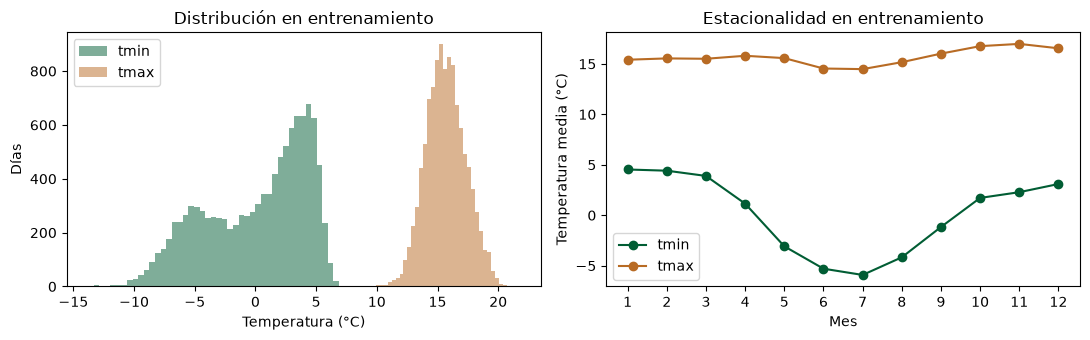

In [14]:
entrenamiento_diario = daily.loc["1981-01-01":"2010-12-31"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for variable, color in [("tmin", "#015D34"), ("tmax", "#B86B24")]:
    valores = entrenamiento_diario.loc[entrenamiento_diario.valido_dia, variable]
    ax[0].hist(valores, bins=45, alpha=0.5, label=variable, color=color)
    medias = valores.groupby(valores.index.month).mean()
    ax[1].plot(medias.index, medias.values, marker="o", label=variable, color=color)
ax[0].set(
    xlabel="Temperatura (°C)", ylabel="Días", title="Distribución en entrenamiento"
)
ax[1].set(
    xlabel="Mes",
    ylabel="Temperatura media (°C)",
    title="Estacionalidad en entrenamiento",
    xticks=range(1, 13),
)
for a in ax:
    a.legend()
fig.tight_layout()
fig.savefig(OUT / "diagnostico_temperaturas_entrenamiento.png", dpi=160)
plt.show()


## 7. Atributos, etiqueta y separación temporal
Para una emisión `t`, los atributos son las siete mínimas y siete máximas de `t−6` a `t`, más seno y coseno del día del año. La etiqueta vale 1 cuando las tres mínimas de `t+1` a `t+3` son ≤ −3 °C. Los días futuros son **objetivo**, nunca atributos.

Las emisiones van del 1 de abril al 27 de septiembre: 180 candidatas por año. Por ahora mostramos entrenamiento y validación; la evaluación de prueba ocurre después de congelar modelos y umbrales.

In [15]:
def make_examples(daily, thermal, min_year=1981, max_year=2020):
    """t-6..t son atributos; t+1..t+3 son objetivo. QC en diez dias."""
    x = pd.DataFrame(index=daily.index)
    for v in ["tmin", "tmax"]:
        for lag in range(6, -1, -1):
            x[f"{v}_lag_{lag}"] = daily[v].shift(lag)
    denominator = np.where(daily.index.is_leap_year, 366.0, 365.0)
    angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
    x["sin_dia"], x["cos_dia"] = np.sin(angle), np.cos(angle)
    history_valid = (
        pd.concat([daily.valido_dia.shift(k) for k in range(7)], axis=1)
        .eq(True)
        .all(axis=1)
    )
    target_valid = (
        pd.concat([daily.valido_dia.shift(-k) for k in range(1, 4)], axis=1)
        .eq(True)
        .all(axis=1)
    )
    future = pd.concat([daily.tmin.shift(-k) for k in range(1, 4)], axis=1)
    past3 = pd.concat([daily.tmin.shift(k) for k in range(3)], axis=1)
    x["valido_historia"], x["valido_objetivo"] = history_valid, target_valid
    x["valido"] = history_valid & target_valid
    x["y"] = future.le(thermal).all(axis=1).astype(float).where(x.valido)
    x["persistencia"] = past3.le(thermal).all(axis=1).astype(float).where(x.valido)
    x["objetivo_inicio"] = x.index + pd.Timedelta(days=1)
    x["objetivo_fin"] = x.index + pd.Timedelta(days=3)
    x["year"], x["month"] = x.index.year, x.index.month
    mmdd = x.index.strftime("%m-%d")
    x = x.loc[
        (mmdd >= "04-01")
        & (mmdd <= "09-27")
        & (x.year >= min_year)
        & (x.year <= max_year)
    ].copy()
    x.index.name = "fecha"
    assert len(x) == 180 * (max_year - min_year + 1)
    assert x.objetivo_fin.dt.month.le(9).all()
    assert (x.objetivo_inicio > x.index).all()
    assert np.isfinite(x.loc[x.valido, FEATURES].to_numpy()).all()
    return x


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


,conjunto,n,positivos,proporción,inicio,fin
0,Entrenamiento,5400,2263,0.419074,1981-04-01,2010-09-27
1,Validación,900,335,0.372222,2011-04-01,2015-09-27


,tmin_lag_6,tmin_lag_5,tmin_lag_4,tmin_lag_3,tmin_lag_2,tmin_lag_1,tmin_lag_0,tmax_lag_6,tmax_lag_5,tmax_lag_4,tmax_lag_3,tmax_lag_2,tmax_lag_1,tmax_lag_0,sin_dia,cos_dia,y,objetivo_inicio,objetivo_fin
fecha,,,,,,,,,,,,,,,,,,,
1981-04-01,3.46,3.00,1.51,0.76,1.98,1.00,1.32,14.550000,16.049999,17.020000,16.590000,15.200000,15.280000,16.110001,0.999991,0.004304,0.0,1981-04-02,1981-04-04
1981-04-02,3.00,1.51,0.76,1.98,1.00,1.32,0.27,16.049999,17.020000,16.590000,15.200000,15.280000,16.110001,15.820000,0.999917,-0.012910,0.0,1981-04-03,1981-04-05
1981-04-03,1.51,0.76,1.98,1.00,1.32,0.27,2.25,17.020000,16.590000,15.200000,15.280000,16.110001,15.820000,15.490000,0.999546,-0.030120,0.0,1981-04-04,1981-04-06
1981-04-04,0.76,1.98,1.00,1.32,0.27,2.25,2.34,16.590000,15.200000,15.280000,16.110001,15.820000,15.490000,14.230000,0.998880,-0.047321,0.0,1981-04-05,1981-04-07
1981-04-05,1.98,1.00,1.32,0.27,2.25,2.34,0.55,15.200000,15.280000,16.110001,15.820000,15.490000,14.230000,13.830000,0.997917,-0.064508,0.0,1981-04-06,1981-04-08
1981-04-06,1.00,1.32,0.27,2.25,2.34,0.55,1.92,15.280000,16.110001,15.820000,15.490000,14.230000,13.830000,13.690000,0.996659,-0.081676,0.0,1981-04-07,1981-04-09


,n,positivos,frecuencia
month,,,
4,900,11.0,0.012222
5,930,347.0,0.373118
6,900,643.0,0.714444
7,930,766.0,0.823656
8,930,423.0,0.454839
9,810,73.0,0.090123


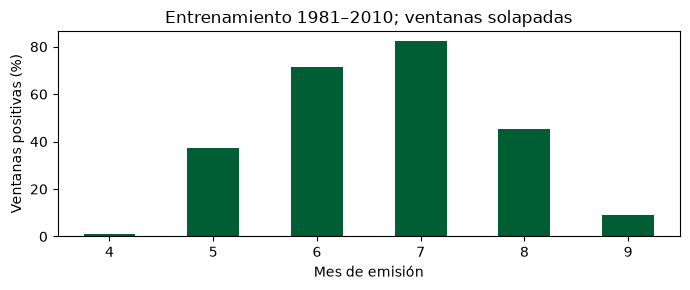

In [16]:
pretest_daily = daily.loc[:"2015-12-31"].copy()
frame = make_examples(pretest_daily, -3, 1981, 2015)
train = frame.loc[frame.valido & frame.year.le(2010)].copy()
val = frame.loc[frame.valido & frame.year.ge(2011)].copy()
assert train.objetivo_fin.max() < val.index.min()

display(
    pd.DataFrame(
        [
            {
                "conjunto": nombre,
                "n": len(g),
                "positivos": int(g.y.sum()),
                "proporción": g.y.mean(),
                "inicio": str(g.index.min().date()),
                "fin": str(g.index.max().date()),
            }
            for nombre, g in [("Entrenamiento", train), ("Validación", val)]
        ]
    )
)
display(train[FEATURES + ["y", "objetivo_inicio", "objetivo_fin"]].head(6))

frecuencia_mes = train.groupby("month").y.agg(
    n="size", positivos="sum", frecuencia="mean"
)
display(frecuencia_mes)
ax = (100 * frecuencia_mes.frecuencia).plot.bar(color="#015D34", rot=0, figsize=(7, 3))
ax.set(
    xlabel="Mes de emisión",
    ylabel="Ventanas positivas (%)",
    title="Entrenamiento 1981–2010; ventanas solapadas",
)
plt.tight_layout()
plt.savefig(OUT / "frecuencia_ventanas_entrenamiento.png", dpi=160)
plt.show()


## 8. Escalado y modelos
**Logística y KNN:** `StandardScaler` se ajusta dentro de cada pipeline, exclusivamente con el entrenamiento de ese pliegue. Validación y prueba reciben esa misma transformación. Así evitamos usar información futura para obtener medias y escalas.

**Árbol:** no requiere estandarización para sus reglas de partición. Se mantiene sin escalar. Se conserva el mismo conjunto de fechas y atributos para comparar los métodos justamente.

La logística utiliza regularización L2; `C` es inverso a su fuerza. KNN usa distancia euclidiana y voto uniforme. El árbol usa Gini y restricciones de profundidad/tamaño de hoja.

In [17]:
def model_factory(name, cfg):
    if name == "logistica":
        # L2 es el valor por defecto con lbfgs; explicitado si la API lo permite.
        return make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=cfg["C"], solver="lbfgs", max_iter=10000, random_state=SEED
            ),
        )
    if name == "arbol":
        return DecisionTreeClassifier(criterion="gini", random_state=SEED, **cfg)
    return make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            weights="uniform", metric="euclidean", algorithm="brute", n_jobs=1, **cfg
        ),
    )


In [18]:
for nombre in ["logistica", "arbol", "knn"]:
    print(nombre)
    display(model_factory(nombre, GRIDS[nombre][0]))
print(
    "Estos objetos muestran la estructura; el ajuste definitivo se realiza más abajo."
)


logistica


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",2026
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0

arbol


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",30
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2026
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

knn


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",31
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_jobs n_jobs: int, 

Estos objetos muestran la estructura; el ajuste definitivo se realiza más abajo.


## 9. Métricas y selección definida antes de la prueba
Se eligen configuraciones por Brier en tres validaciones crecientes dentro de 1981–2010. Después se ajusta con 1981–2010 y se utiliza 2011–2015 para elegir α, umbrales y principal.

F₀,₅ expresa una preferencia por precisión de los avisos; no acredita una relación de costos económicos. F1 es secundario. La mezcla suma las probabilidades de logística y árbol; persistencia y frecuencia mensual son las referencias. Las reglas de empate están escritas en el código y se guardan en `freeze.json`.

In [19]:
def score(y, p, pred, beta=0.5):
    y, p, pred = (
        np.asarray(y, dtype=int),
        np.asarray(p, dtype=float),
        np.asarray(pred, dtype=bool),
    )
    n = len(y)
    tp = int(((y == 1) & pred).sum())
    fp = int(((y == 0) & pred).sum())
    fn = int(((y == 1) & ~pred).sum())
    tn = int(((y == 0) & ~pred).sum())
    positive = tp + fn
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / positive if positive else np.nan

    def f(b):
        return (
            (1 + b * b) * tp / ((1 + b * b) * tp + fp + b * b * fn)
            if positive
            else np.nan
        )

    return {
        "n": n,
        "positivos": positive,
        "prevalencia": positive / n if n else np.nan,
        "avisos": tp + fp,
        "VP": tp,
        "FP": fp,
        "FN": fn,
        "VN": tn,
        "precision": precision,
        "recall": recall,
        "F0.5": f(0.5),
        "F1": f(1.0),
        "Fbeta": f(beta),
        "Brier": float(np.mean((p - y) ** 2)) if n else np.nan,
        "average_precision": (
            float(average_precision_score(y, p)) if positive else np.nan
        ),
    }


def choose_threshold(y, probs, beta):
    """Empates numericos <=1e-12 favorecen tau mayor; aviso p>=tau."""
    candidates = np.r_[np.unique(probs), np.nextafter(float(np.max(probs)), np.inf)]
    rows = []
    for tau in candidates:
        s = score(y, probs, probs >= tau, beta)
        rows.append(
            {
                "tau": float(tau),
                "Fbeta": s["Fbeta"],
                "precision": s["precision"],
                "recall": s["recall"],
                "VP": s["VP"],
                "FP": s["FP"],
                "FN": s["FN"],
            }
        )
    table = pd.DataFrame(rows)
    if not np.isfinite(table.Fbeta).any():
        raise ValueError("No hay positivos en validacion; no puede ajustarse Fbeta")
    best = table.Fbeta.max()
    selected = table.loc[np.isclose(table.Fbeta, best, atol=1e-12, rtol=0)].tau.max()
    return float(selected), table


def select_principal(metrics):
    best_f = max(metrics[m]["Fbeta"] for m in CLASSIFIERS)
    tied = [
        m
        for m in CLASSIFIERS
        if np.isclose(metrics[m]["Fbeta"], best_f, atol=1e-12, rtol=0)
    ]
    best_b = min(metrics[m]["Brier"] for m in tied)
    return next(
        m for m in tied if np.isclose(metrics[m]["Brier"], best_b, atol=1e-12, rtol=0)
    )


In [20]:
def select_config(name, frame, thermal):
    rows, candidate_rows = [], []
    for cfg_idx, cfg in enumerate(GRIDS[name]):
        bs = []
        for fold, (train_start, train_end, eval_start, eval_end) in enumerate(FOLDS, 1):
            tr = frame.loc[frame.valido & frame.year.between(train_start, train_end)]
            va = frame.loc[frame.valido & frame.year.between(eval_start, eval_end)]
            assert tr.objetivo_fin.max() < va.index.min()
            model = model_factory(name, cfg)
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                model.fit(tr[FEATURES], tr.y.astype(int))
            if name != "arbol":
                assert np.allclose(
                    model[0].mean_, tr[FEATURES].mean().to_numpy(), atol=1e-10
                )
            p = model.predict_proba(va[FEATURES])[:, 1]
            brier = float(np.mean((p - va.y.to_numpy()) ** 2))
            bs.append(brier)
            rows.append(
                {
                    "thermal": thermal,
                    "model": name,
                    "candidate": cfg_idx,
                    "params": json.dumps(cfg, sort_keys=True),
                    "fold": fold,
                    "train_start": train_start,
                    "train_end": train_end,
                    "eval_start": eval_start,
                    "eval_end": eval_end,
                    "n_train": len(tr),
                    "n_eval": len(va),
                    "Brier": brier,
                }
            )
        candidate_rows.append(
            {
                "thermal": thermal,
                "model": name,
                "candidate": cfg_idx,
                "params": json.dumps(cfg, sort_keys=True),
                "Brier_mean": float(np.mean(bs)),
                "Brier_std_population": float(np.std(bs)),
            }
        )
    best_score = min(r["Brier_mean"] for r in candidate_rows)
    tied = [
        r
        for r in candidate_rows
        if np.isclose(r["Brier_mean"], best_score, atol=1e-12, rtol=0)
    ]
    # Orden de la rejilla: menor C, menor profundidad/mayor hoja, mayor k.
    winner = min(tied, key=lambda r: r["candidate"])
    for r in candidate_rows:
        r["selected"] = r["candidate"] == winner["candidate"]
    return GRIDS[name][winner["candidate"]], rows, candidate_rows


In [21]:
def episodes(daily, thermal, first_year, last_year):
    """Rachas maximales dentro de abril-septiembre; episodios son >=3 dias.

    Un episodio de L dias contiene L-2 subventanas completas, pero las
    emisiones cubren objetivos desde 2/abril: documentar esta frontera.
    """
    rows = []
    for year in range(first_year, last_year + 1):
        d = daily.loc[f"{year}-04-01":f"{year}-09-30"]
        cold = (d.valido_dia & (d.tmin <= thermal)).to_numpy()
        starts = np.flatnonzero(cold & ~np.r_[False, cold[:-1]])
        ends = np.flatnonzero(cold & ~np.r_[cold[1:], False])
        for start, end in zip(starts, ends):
            length = int(end - start + 1)
            if length >= 3:
                rows.append(
                    {
                        "thermal": thermal,
                        "year": year,
                        "inicio": str(d.index[start].date()),
                        "fin": str(d.index[end].date()),
                        "dias": length,
                        "tmin_min": float(d.tmin.iloc[start : end + 1].min()),
                        "subventanas_tres_dias": length - 2,
                        "toca_borde_temporada": bool(start == 0 or end == len(d) - 1),
                    }
                )
    return pd.DataFrame(
        rows,
        columns=[
            "thermal",
            "year",
            "inicio",
            "fin",
            "dias",
            "tmin_min",
            "subventanas_tres_dias",
            "toca_borde_temporada",
        ],
    )


def sanity_tests(daily):
    # Modificar el futuro no puede cambiar atributos del presente.
    ref = make_examples(daily.loc[:"2015-12-31"], -3, 1981, 2015)
    d = pd.Timestamp("2010-06-15")
    changed = daily.loc[:"2015-12-31"].copy()
    changed.loc[d + pd.Timedelta(days=1) :, ["tmin", "tmax"]] += 100
    new = make_examples(changed, -3, 1981, 2015)
    assert np.array_equal(
        ref.loc[d, FEATURES].to_numpy(), new.loc[d, FEATURES].to_numpy()
    )
    assert ref.loc[d, "objetivo_fin"] == d + pd.Timedelta(days=3)
    assert list(ref.loc[d, [f"tmin_lag_{i}" for i in range(6, -1, -1)]]) == list(
        daily.loc[d - pd.Timedelta(days=6) : d, "tmin"]
    )
    assert all(
        make_examples(daily, -3, y, y).shape[0] == 180 for y in [1981, 1984, 2016, 2020]
    )
    s = score([1, 1, 0], [0.8, 0.2, 0.7], [1, 0, 1])
    assert np.isclose(s["F0.5"], 1.25 / (1.25 + 1 + 0.25))
    z = score([0, 0], [0.1, 0.2], [0, 0])
    assert z["precision"] == 0 and np.isnan(z["recall"]) and np.isnan(z["F0.5"])
    # QC: un dia invalido invalida t-6..t+3, sin rellenar el objetivo.
    bad = daily.copy()
    bad.loc[d, "valido_dia"] = False
    check = make_examples(bad, -3, 2010, 2010)
    assert not check.loc[
        d - pd.Timedelta(days=3) : d + pd.Timedelta(days=6), "valido"
    ].any()
    assert (
        check.loc[d - pd.Timedelta(days=4), "valido"]
        == make_examples(daily, -3, 2010, 2010).loc[d - pd.Timedelta(days=4), "valido"]
    )
    return {
        "future_perturbation_does_not_change_features": True,
        "exact_feature_alignment": True,
        "three_future_days": True,
        "180_candidate_dates_per_year": True,
        "Fbeta_formula": True,
        "no_positives_convention": True,
        "invalid_full_window_no_imputation": True,
        "temporal_folds_no_overlap_and_train_scalers_checked_during_fit": True,
    }


In [22]:
comprobaciones = sanity_tests(daily)
display(pd.DataFrame(comprobaciones.items(), columns=["comprobación", "cumple"]))


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_yea

C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


,comprobación,cumple
0,future_perturbation_does_not_change_features,True
1,exact_feature_alignment,True
2,three_future_days,True
3,180_candidate_dates_per_year,True
4,Fbeta_formula,True
5,no_positives_convention,True
6,invalid_full_window_no_imputation,True
7,temporal_folds_no_overlap_and_train_scalers_ch...,True


## 10. Funciones de ejecución y controles de integridad
Las siguientes funciones implementan el protocolo completo. Se definen aquí, pero **definir `test()` no ejecuta la prueba**. Su llamada se reserva para la sección 12. La preparación comprueba también que los escaladores finales contienen solo las 5400 observaciones de entrenamiento.

In [23]:
def auditar_escaladores(state, daily, out):
    """Comprueba las medias y escalas de los modelos finales contra 1981–2010."""
    rows = []
    for key, st in state.items():
        frame = make_examples(daily.loc[:"2015-12-31"], float(key), 1981, 2015)
        train = frame.loc[frame.valido & frame.year.le(2010), FEATURES]
        for name in ["logistica", "knn"]:
            scaler = st["models"][name][0]
            assert int(scaler.n_samples_seen_) == len(train)
            assert np.allclose(scaler.mean_, train.mean().to_numpy(), atol=1e-10)
            assert np.allclose(scaler.var_, train.var(ddof=0).to_numpy(), atol=1e-10)
            z = scaler.transform(train)
            assert np.allclose(z.mean(axis=0), 0, atol=1e-10)
            for j, feature in enumerate(FEATURES):
                rows.append(
                    {
                        "thermal": float(key),
                        "model": name,
                        "feature": feature,
                        "n_fit": len(train),
                        "training_mean": scaler.mean_[j],
                        "training_scale": scaler.scale_[j],
                        "transformed_training_mean": z[:, j].mean(),
                        "transformed_training_std": z[:, j].std(),
                        "periodo_fit": "1981-2010",
                        "usa_validacion_o_prueba_en_fit": False,
                    }
                )
    save_csv(pd.DataFrame(rows), out / "auditoria_escalado.csv")


In [24]:
def prepare(data_dir, out, extracted=None):
    begin = time.perf_counter()
    out.mkdir(parents=True, exist_ok=True)
    daily, manifest, audit = (
        extracted if extracted is not None else extract_cell(data_dir, out)
    )
    describir_preprocesamiento(daily, out)
    tests = sanity_tests(daily)
    write_json(out / "sanity_tests.json", tests)
    # No ejemplos, etiquetas ni probabilidades de prueba durante seleccion.
    pretest_daily = daily.loc[:"2015-12-31"].copy()
    (
        all_cv,
        all_means,
        all_val,
        all_alpha,
        all_thresholds,
        all_pop,
        all_month,
        all_eps,
    ) = ([], [], [], [], [], [], [], [])
    state, decisions = {}, {}
    for thermal in THERMALS:
        print(f"PREPARE thermal={thermal:g}; solo 1981-2015", flush=True)
        frame = make_examples(pretest_daily, thermal, 1981, 2015)
        train = frame.loc[frame.valido & frame.year.le(2010)]
        val = frame.loc[frame.valido & frame.year.ge(2011)]
        configs, fitted = {}, {}
        for name in GRIDS:
            cfg, cvrows, means = select_config(name, frame, thermal)
            configs[name] = cfg
            all_cv.extend(cvrows)
            all_means.extend(means)
            fitted[name] = model_factory(name, cfg)
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                fitted[name].fit(train[FEATURES], train.y.astype(int))
        probs = {n: fitted[n].predict_proba(val[FEATURES])[:, 1] for n in fitted}
        monthly = train.groupby("month").y.mean().to_dict()
        probs["frecuencia_mensual"] = val.month.map(monthly).to_numpy()
        probs["persistencia"] = val.persistencia.to_numpy()
        arows = []
        for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:
            p = alpha * probs["logistica"] + (1 - alpha) * probs["arbol"]
            arows.append(
                {
                    "thermal": thermal,
                    "alpha": alpha,
                    "Brier": float(np.mean((p - val.y.to_numpy()) ** 2)),
                }
            )
        low = min(r["Brier"] for r in arows)
        alpha = max(
            r["alpha"] for r in arows if np.isclose(r["Brier"], low, atol=1e-12, rtol=0)
        )
        for r in arows:
            r["selected"] = r["alpha"] == alpha
        all_alpha.extend(arows)
        probs["mezcla"] = alpha * probs["logistica"] + (1 - alpha) * probs["arbol"]
        if alpha in [0.0, 1.0]:
            assert np.array_equal(
                probs["mezcla"], probs["logistica" if alpha == 1 else "arbol"]
            )
        decisions_by_beta = {}
        for beta in [0.5, 1.0]:
            thresholds, metrics = {}, {}
            for name in MODELS:
                if name == "persistencia":
                    tau = 0.5
                else:
                    tau, table = choose_threshold(val.y.to_numpy(), probs[name], beta)
                    table["thermal"], table["beta"], table["model"] = (
                        thermal,
                        beta,
                        name,
                    )
                    all_thresholds.extend(table.to_dict("records"))
                thresholds[name] = tau
                metrics[name] = score(val.y, probs[name], probs[name] >= tau, beta)
                all_val.append(
                    {
                        "thermal": thermal,
                        "beta": beta,
                        "model": name,
                        "tau": tau,
                        **metrics[name],
                    }
                )
            principal = select_principal(metrics)
            decisions_by_beta[str(beta)] = {
                "thresholds": thresholds,
                "principal": principal,
                "validation_metrics": metrics,
            }
        key = str(int(thermal))
        decisions[key] = {
            "thermal": thermal,
            "selected_configs": configs,
            "alpha": alpha,
            "monthly_training_frequencies": monthly,
            "decisions_by_beta": decisions_by_beta,
            "training_n": len(train),
            "validation_n": len(val),
        }
        state[key] = {
            "models": fitted,
            "monthly": monthly,
            "validation_dates": val.index,
            "validation_probs": probs,
        }
        pred_val = val[["y", "persistencia", "objetivo_inicio", "objetivo_fin"]].copy()
        for n in MODELS:
            pred_val[f"p_{n}"] = probs[n]
        save_csv(
            pred_val.reset_index(),
            out / f"predicciones_validacion_m{abs(int(thermal))}.csv",
        )
        for label, a, b in [("entrenamiento", 1981, 2010), ("validacion", 2011, 2015)]:
            sub = frame.loc[frame.year.between(a, b)]
            all_pop.append(
                {
                    "thermal": thermal,
                    "split": label,
                    "candidate_n": len(sub),
                    "valid_n": int(sub.valido.sum()),
                    "invalid_n": int((~sub.valido).sum()),
                    "positive_n": int(sub.y.sum()),
                    "prevalence": float(sub.y.mean()),
                }
            )
        for month, g in train.groupby("month"):
            all_month.append(
                {
                    "thermal": thermal,
                    "month": month,
                    "n": len(g),
                    "positive_n": int(g.y.sum()),
                    "window_frequency": float(g.y.mean()),
                    "tmin_mean": float(g.tmin_lag_0.mean()),
                    "tmin_min": float(g.tmin_lag_0.min()),
                    "tmax_mean": float(g.tmax_lag_0.mean()),
                }
            )
        all_eps.append(episodes(pretest_daily, thermal, 1981, 2015))
        print(
            f"  configs={configs}; alpha={alpha}; principal={decisions_by_beta['0.5']['principal']}",
            flush=True,
        )
    write_json(
        out / "freeze.json",
        {
            "protocol_version": "1.0",
            "seed": SEED,
            "feature_order": FEATURES,
            "thermal_definitions": THERMALS,
            "train": "1981-2010",
            "validation": "2011-2015",
            "test": "2016-2020 (NO EVALUADO EN ESTA FASE)",
            "model_fit_uses_validation": False,
            "season_emission": "04-01..09-27 inclusive; 180/y",
            "target": "all three tmin(t+1:t+3) <= thermal",
            "seasonal_encoding": "sin/cos(2*pi*dayofyear/D), D=365 or 366 of emission year",
            "alpha_formula": "alpha*LR+(1-alpha)*tree",
            "alpha_tie": "higher alpha",
            "tie_tolerance_absolute": 1e-12,
            "threshold_rule": "p>=tau; candidates unique validation probabilities + nextafter(max,+inf); Fbeta tie higher tau",
            "config_tie": "lower C; lower depth then larger leaf; larger k",
            "principal_tie": "higher validation Fbeta, then lower Brier, then LR/tree/KNN/mix",
            "beta1_scope": "secondary; same configurations, fitted models, probabilities and alpha as beta0.5",
            "bootstrap": "1000 paired calendar moving-block samples; six blocks of30 per season within each of five fixed test years; shared mask and indices; seed2026",
            "sources": manifest,
            "code_sha256": huella_codigo(),
            "code_hash_scope": "Funciones ejecutadas y parámetros predefinidos; codigo_ejecutado.py",
            "versions": {
                "python": platform.python_version(),
                "numpy": np.__version__,
                "pandas": pd.__version__,
                "sklearn": sklearn.__version__,
            },
            "decisions": decisions,
        },
    )
    joblib.dump(state, out / "modelos_congelados.joblib", compress=3)
    auditar_escaladores(state, daily, out)
    (out / "codigo_ejecutado.py").write_text(
        codigo_fuente_ejecutado(), encoding="utf-8"
    )
    for name, rows in [
        ("cv_folds", all_cv),
        ("cv_resumen", all_means),
        ("metricas_validacion", all_val),
        ("alpha_validacion", all_alpha),
        ("busqueda_umbrales_validacion", all_thresholds),
        ("prevalencia_pretest", all_pop),
        ("eda_mensual_entrenamiento", all_month),
    ]:
        save_csv(pd.DataFrame(rows), out / f"{name}.csv")
    save_csv(pd.concat(all_eps, ignore_index=True), out / "episodios_pretest.csv")
    write_json(out / "timing_prepare.json", {"seconds": time.perf_counter() - begin})
    print("FREEZE ESCRITO. La fase prepare termina sin evaluar la prueba.", flush=True)


El bootstrap usa 1000 réplicas pareadas de bloques de 30 días calendario dentro de cada temporada. Los intervalos son exploratorios y condicionan a los modelos ya ajustados y a cinco temporadas. No se interpretan como validación productiva ni prueba confirmatoria de significancia.

In [25]:
def bootstrap_test(frame, probs, decision, thermal, beta, n_boot=1000):
    """Remuestreo por calendario antes de la mascara, pareado entre metodos."""
    rng = np.random.default_rng(SEED)
    years = sorted(frame.year.unique())
    assert len(years) == 5 and len(frame) == 900
    y = frame.y.to_numpy()
    valid = frame.valido.to_numpy()
    allp = {n: np.asarray(probs[n], float) for n in MODELS}
    thresholds = decision["thresholds"]
    principal = decision["principal"]
    rows, deltas = [], []
    draws = np.empty((n_boot, 5, 6), dtype=np.int16)
    # Inicios0..150 inclusive: ningun bloque cruza septiembre o cambia de ano.
    for rep in range(n_boot):
        picks = []
        for j, yr in enumerate(years):
            locations = np.flatnonzero(frame.year.to_numpy() == yr)
            assert len(locations) == 180
            starts = rng.integers(0, 151, size=6)
            draws[rep, j] = starts
            picks.extend(locations[(starts[:, None] + np.arange(30)).ravel()].tolist())
        idx = np.asarray(picks, dtype=int)
        idx = idx[valid[idx]]
        scores = {}
        for name in MODELS:
            p = allp[name][idx]
            scores[name] = score(y[idx], p, p >= thresholds[name], beta)
            rows.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "model": name,
                    **{
                        k: scores[name][k]
                        for k in [
                            "n",
                            "positivos",
                            "precision",
                            "recall",
                            "F0.5",
                            "F1",
                            "Fbeta",
                            "Brier",
                        ]
                    },
                }
            )
        for comparator in MODELS:
            if comparator == principal:
                continue
            deltas.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "principal": principal,
                    "comparador": comparator,
                    "delta_F0.5": scores[principal]["F0.5"]
                    - scores[comparator]["F0.5"],
                    "delta_F1": scores[principal]["F1"] - scores[comparator]["F1"],
                    "delta_Brier": scores[principal]["Brier"]
                    - scores[comparator]["Brier"],
                }
            )
        for comparator in ["logistica", "arbol"]:
            deltas.append(
                {
                    "replica": rep,
                    "thermal": thermal,
                    "beta": beta,
                    "principal": "mezcla",
                    "comparador": comparator,
                    "delta_F0.5": scores["mezcla"]["F0.5"] - scores[comparator]["F0.5"],
                    "delta_F1": scores["mezcla"]["F1"] - scores[comparator]["F1"],
                    "delta_Brier": scores["mezcla"]["Brier"]
                    - scores[comparator]["Brier"],
                }
            )
    return (
        pd.DataFrame(rows),
        pd.DataFrame(deltas).drop_duplicates(
            ["replica", "thermal", "beta", "principal", "comparador"]
        ),
        draws,
    )


def intervals(table, groupcols, values):
    rows = []
    for key, g in table.groupby(groupcols, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        for value in values:
            arr = g[value].to_numpy()
            valid = arr[np.isfinite(arr)]
            rows.append(
                {
                    **dict(zip(groupcols, key)),
                    "metric": value,
                    "lower_2.5": (
                        float(np.percentile(valid, 2.5)) if len(valid) else np.nan
                    ),
                    "upper_97.5": (
                        float(np.percentile(valid, 97.5)) if len(valid) else np.nan
                    ),
                    "replicas_estimables": len(valid),
                    "replicas_totales": len(g),
                    "fraction_not_estimable": 1 - len(valid) / len(g),
                }
            )
    return pd.DataFrame(rows)


In [26]:
def resumir(out):
    out = Path(out)
    avisos = pd.read_csv(out / "predicciones_prueba_m3.csv")
    episodios = pd.read_csv(out / "episodios_prueba.csv")
    episodios = episodios.loc[episodios.thermal == -3]
    validos = avisos["valido"].astype(bool)
    a = avisos.loc[validos, "aviso_beta0.5_logistica"]
    b = avisos.loc[validos, "aviso_beta0.5_arbol"]
    resultado = {
        "alcance": "Descripcion posterior de salidas, sin nuevas decisiones de ajuste",
        "thermal": -3,
        "beta": 0.5,
        "n": int(validos.sum()),
        "desacuerdo_avisos_logistica_arbol": int((a != b).sum()),
        "fraccion_desacuerdo": float((a != b).mean()),
        "episodios_prueba": len(episodios),
        "episodios_por_ano": {
            str(int(k)): int(v) for k, v in episodios.groupby("year").size().items()
        },
        "subventanas_en_episodios": int(episodios.subventanas_tres_dias.sum()),
        "positivos_prueba": int(avisos.loc[validos, "y"].sum()),
        "episodios_tocan_borde": int(episodios.toca_borde_temporada.sum()),
    }
    (out / "resumen_descriptivo.json").write_text(
        json.dumps(resultado, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    return resultado


In [27]:
def test(out):
    begin = time.perf_counter()
    frozen = json.loads((out / "freeze.json").read_text(encoding="utf-8"))
    assert (
        frozen["code_sha256"] == huella_codigo()
    ), "El codigo cambio despues de congelar decisiones"
    state = joblib.load(out / "modelos_congelados.joblib")
    daily = pd.read_csv(
        out / "celda_diaria.csv", parse_dates=["fecha"], float_precision="round_trip"
    ).set_index("fecha")
    allmetrics, allannual, allpop, eps = [], [], [], []
    boot_tables, delta_tables = [], []
    for thermal in THERMALS:
        print(f"TEST thermal={thermal:g}; ninguna decision se reajusta", flush=True)
        key = str(int(thermal))
        f = frozen["decisions"][key]
        st = state[key]
        frame = make_examples(daily, thermal, 2016, 2020)
        valid = frame.valido.to_numpy()
        sub = frame.loc[frame.valido]
        probs = {}
        for n, m in st["models"].items():
            probs[n] = np.full(len(frame), np.nan)
            probs[n][valid] = m.predict_proba(sub[FEATURES])[:, 1]
        probs["frecuencia_mensual"] = frame.month.map(st["monthly"]).to_numpy(
            dtype=float
        )
        probs["persistencia"] = frame.persistencia.to_numpy()
        probs["mezcla"] = (
            f["alpha"] * probs["logistica"] + (1 - f["alpha"]) * probs["arbol"]
        )
        if f["alpha"] in [0.0, 1.0]:
            assert np.array_equal(
                probs["mezcla"][valid],
                probs["logistica" if f["alpha"] == 1 else "arbol"][valid],
            )
        predictions = frame[
            [
                "objetivo_inicio",
                "objetivo_fin",
                "year",
                "month",
                "valido_historia",
                "valido_objetivo",
                "valido",
                "y",
            ]
        ].copy()
        for name in MODELS:
            predictions[f"p_{name}"] = probs[name]
        for beta in [0.5, 1.0]:
            dec = f["decisions_by_beta"][str(beta)]
            for name in MODELS:
                tau = dec["thresholds"][name]
                prediction = probs[name] >= tau
                predictions[f"aviso_beta{beta}_{name}"] = pd.Series(
                    prediction.astype(float), index=frame.index
                ).where(frame.valido)
                allmetrics.append(
                    {
                        "thermal": thermal,
                        "beta": beta,
                        "model": name,
                        "principal": name == dec["principal"],
                        "tau": tau,
                        **score(
                            frame.y[valid], probs[name][valid], prediction[valid], beta
                        ),
                    }
                )
                for year in range(2016, 2021):
                    mask = valid & (frame.year.to_numpy() == year)
                    allannual.append(
                        {
                            "thermal": thermal,
                            "beta": beta,
                            "model": name,
                            "year": year,
                            "principal": name == dec["principal"],
                            **score(
                                frame.y[mask], probs[name][mask], prediction[mask], beta
                            ),
                        }
                    )
            b, d, draws = bootstrap_test(frame, probs, dec, thermal, beta)
            boot_tables.append(b)
            delta_tables.append(d)
            if thermal == -3 and beta == 0.5:
                np.save(out / "bootstrap_inicios_calendario.npy", draws)
        save_csv(
            predictions.reset_index(),
            out / f"predicciones_prueba_m{abs(int(thermal))}.csv",
        )
        allpop.append(
            {
                "thermal": thermal,
                "split": "prueba",
                "candidate_n": len(frame),
                "valid_n": int(valid.sum()),
                "invalid_n": int((~valid).sum()),
                "positive_n": int(frame.y.sum()),
                "prevalence": float(frame.y.mean()),
            }
        )
        eps.append(episodes(daily, thermal, 2016, 2020))
    metrics = pd.DataFrame(allmetrics)
    annual = pd.DataFrame(allannual)
    boot = pd.concat(boot_tables, ignore_index=True)
    deltas = pd.concat(delta_tables, ignore_index=True)
    save_csv(metrics, out / "metricas_prueba.csv")
    save_csv(annual, out / "metricas_prueba_anuales.csv")
    save_csv(pd.DataFrame(allpop), out / "prevalencia_prueba.csv")
    save_csv(pd.concat(eps, ignore_index=True), out / "episodios_prueba.csv")
    save_csv(boot, out / "bootstrap_metricas_1000.csv")
    save_csv(deltas, out / "bootstrap_diferencias_1000.csv")
    save_csv(
        intervals(
            boot,
            ["thermal", "beta", "model"],
            ["precision", "recall", "F0.5", "F1", "Brier"],
        ),
        out / "bootstrap_intervalos_metricas.csv",
    )
    save_csv(
        intervals(
            deltas,
            ["thermal", "beta", "principal", "comparador"],
            ["delta_F0.5", "delta_F1", "delta_Brier"],
        ),
        out / "bootstrap_intervalos_diferencias.csv",
    )
    # Hipotesis fijadas: comparar puntos estrictamente, sin llamarlos significativos.
    conclusions = {}
    for thermal in THERMALS:
        key = str(int(thermal))
        sel = frozen["decisions"][key]["decisions_by_beta"]["0.5"]["principal"]
        g = metrics.loc[(metrics.thermal == thermal) & (metrics.beta == 0.5)].set_index(
            "model"
        )
        diffs = {
            ref: float(g.loc[sel, "F0.5"] - g.loc[ref, "F0.5"])
            for ref in ["persistencia", "frecuencia_mensual"]
        }
        md = {
            ref: float(g.loc["mezcla", "Brier"] - g.loc[ref, "Brier"])
            for ref in ["logistica", "arbol"]
        }
        conclusions[key] = {
            "principal": sel,
            "alpha": frozen["decisions"][key]["alpha"],
            "delta_F0.5_vs_referencias": diffs,
            "hipotesis_principal_apoyada_puntualmente": all(
                v > 0 for v in diffs.values()
            ),
            "delta_Brier_mezcla_vs_componentes": md,
            "hipotesis_complementaria_apoyada_puntualmente": all(
                v < 0 for v in md.values()
            ),
            "scope": "Puntos historicos; intervalos bootstrap exploratorios, no prueba de significancia ni validacion productiva.",
        }
    write_json(out / "conclusiones_numericas.json", conclusions)
    write_json(
        out / "timing_test.json",
        {
            "seconds": time.perf_counter() - begin,
            "freeze_sha256": sha(out / "freeze.json"),
            "bootstrap_replicates": 1000,
        },
    )
    print(
        metrics.loc[(metrics.thermal == -3) & (metrics.beta == 0.5)].to_string(
            index=False
        ),
        flush=True,
    )
    resumir(out)
    print(
        json.dumps(clean_json(conclusions["-3"]), ensure_ascii=False, indent=2),
        flush=True,
    )


## 11. Entrenar, validar y congelar las decisiones
Esta llamada vuelve a entrenar los modelos desde la celda que acabamos de leer de los NetCDF. No reutiliza modelos guardados del informe. Los archivos de prueba no se utilizan para ajustar parámetros, pesos, umbrales o el modelo principal.

In [28]:
prepare(DATA, OUT, extracted=(daily, manifest, audit))
frozen = json.loads((OUT / "freeze.json").read_text(encoding="utf-8"))
principal = frozen["decisions"]["-3"]["decisions_by_beta"]["0.5"]["principal"]
print("Modelo principal fijado en validación:", principal)
print("Configuraciones:", frozen["decisions"]["-3"]["selected_configs"])
print("Alpha:", frozen["decisions"]["-3"]["alpha"])
display(pd.read_csv(OUT / "cv_resumen.csv").query("thermal == -3"))
display(
    pd.read_csv(OUT / "metricas_validacion.csv").query("thermal == -3 and beta == 0.5")
)


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_yea

PREPARE thermal=-3; solo 1981-2015


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_yea

  configs={'logistica': {'C': 0.1}, 'arbol': {'max_depth': 3, 'min_samples_leaf': 30}, 'knn': {'n_neighbors': 31}}; alpha=0.75; principal=logistica


PREPARE thermal=-2; solo 1981-2015


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


... (6 outputs left out)

FREEZE ESCRITO. La fase prepare termina sin evaluar la prueba.


Modelo principal fijado en validación: logistica
Configuraciones: {'arbol': {'max_depth': 3, 'min_samples_leaf': 30}, 'knn': {'n_neighbors': 31}, 'logistica': {'C': 0.1}}
Alpha: 0.75


,thermal,model,candidate,params,Brier_mean,Brier_std_population,selected
0,-3,logistica,0,"{""C"": 0.1}",0.126004,0.003029,True
1,-3,logistica,1,"{""C"": 1.0}",0.126050,0.002789,False
2,-3,logistica,2,"{""C"": 10.0}",0.126075,0.002767,False
3,-3,arbol,0,"{""max_depth"": 3, ""min_samples_leaf"": 30}",0.132559,0.003100,True
4,-3,arbol,1,"{""max_depth"": 3, ""min_samples_leaf"": 10}",0.132559,0.003100,False
5,-3,arbol,2,"{""max_depth"": 5, ""min_samples_leaf"": 30}",0.137471,0.003406,False
6,-3,arbol,3,"{""max_depth"": 5, ""min_samples_leaf"": 10}",0.139037,0.007454,False
7,-3,arbol,4,"{""max_depth"": 8, ""min_samples_leaf"": 30}",0.145376,0.002852,False
8,-3,arbol,5,"{""max_depth"": 8, ""min_samples_leaf"": 10}",0.160180,0.005837,False
9,-3,knn,0,"{""n_neighbors"": 31}",0.138362,0.003388,True


,thermal,beta,model,tau,n,positivos,prevalencia,avisos,VP,FP,FN,VN,precision,recall,F0.5,F1,Fbeta,Brier,average_precision
0,-3,0.5,logistica,0.551970,900,335,0.372222,361,265,96,70,469,0.734072,0.791045,0.744800,0.761494,0.744800,0.135937,0.765042
1,-3,0.5,arbol,0.739496,900,335,0.372222,319,236,83,99,482,0.739812,0.704478,0.732464,0.721713,0.732464,0.143761,0.708986
2,-3,0.5,knn,0.612903,900,335,0.372222,318,230,88,105,477,0.723270,0.686567,0.715619,0.704441,0.715619,0.147760,0.703475
3,-3,0.5,mezcla,0.526763,900,335,0.372222,365,266,99,69,466,0.728767,0.794030,0.740947,0.760000,0.740947,0.135915,0.766517
4,-3,0.5,frecuencia_mensual,0.714444,900,335,0.372222,305,210,95,125,470,0.688525,0.626866,0.675241,0.656250,0.675241,0.165130,0.662171
5,-3,0.5,persistencia,0.500000,900,335,0.372222,335,222,113,113,452,0.662687,0.662687,0.662687,0.662687,0.662687,0.251111,0.564709


In [29]:
escalado = pd.read_csv(OUT / "auditoria_escalado.csv")
display(escalado.query("thermal == -3"))
assert (escalado.n_fit == 5400).all()
assert not escalado.usa_validacion_o_prueba_en_fit.any()
assert np.allclose(escalado.transformed_training_mean, 0, atol=1e-10)
print("ESCALADO VERIFICADO: medias y escalas aprendidas solo en entrenamiento.")
assert frozen["code_sha256"] == huella_codigo()
print("DECISIONES CONGELADAS. Ahora corresponde evaluar la prueba.")


,thermal,model,feature,n_fit,training_mean,training_scale,transformed_training_mean,transformed_training_std,periodo_fit,usa_validacion_o_prueba_en_fit
0,-3,logistica,tmin_lag_6,5400,-3.034661,3.506569,6.579099e-17,1,1981-2010,False
1,-3,logistica,tmin_lag_5,5400,-3.054030,3.481980,-6.447517e-17,1,1981-2010,False
2,-3,logistica,tmin_lag_4,5400,-3.074089,3.457527,6.052771e-17,1,1981-2010,False
3,-3,logistica,tmin_lag_3,5400,-3.092989,3.432958,8.947575e-17,1,1981-2010,False
4,-3,logistica,tmin_lag_2,5400,-3.110378,3.408472,-5.263280e-17,1,1981-2010,False
5,-3,logistica,tmin_lag_1,5400,-3.129291,3.382484,-1.973730e-17,1,1981-2010,False
6,-3,logistica,tmin_lag_0,5400,-3.149720,3.355496,-4.473788e-17,1,1981-2010,False
7,-3,logistica,tmax_lag_6,5400,15.222969,1.450404,-8.421247e-17,1,1981-2010,False
8,-3,logistica,tmax_lag_5,5400,15.225893,1.452098,6.105404e-16,1,1981-2010,False
9,-3,logistica,tmax_lag_4,5400,15.229970,1.454978,3.473764e-16,1,1981-2010,False


ESCALADO VERIFICADO: medias y escalas aprendidas solo en entrenamiento.
DECISIONES CONGELADAS. Ahora corresponde evaluar la prueba.


## 12. Prueba reservada: 2016–2020
La función comprueba que el código siga siendo el mismo y conserva las decisiones de validación. Genera probabilidades, avisos, matrices de confusión, métricas, resultados anuales y sensibilidad térmica. No vuelve a seleccionar con los resultados de prueba.

In [30]:
test(OUT)
metricas = pd.read_csv(OUT / "metricas_prueba.csv")
principal_test = metricas.query("thermal == -3 and beta == 0.5").copy()
display(
    principal_test[
        [
            "model",
            "principal",
            "tau",
            "n",
            "positivos",
            "VP",
            "FP",
            "FN",
            "VN",
            "precision",
            "recall",
            "F0.5",
            "F1",
            "Brier",
        ]
    ]
)
print((OUT / "conclusiones_numericas.json").read_text(encoding="utf-8"))


TEST thermal=-3; ninguna decision se reajusta


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3727936275.py:8: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  daily = pd.read_csv(
C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


TEST thermal=-2; ninguna decision se reajusta


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


TEST thermal=-4; ninguna decision se reajusta


C:\Users\51924\AppData\Local\Temp\ipykernel_29516\3822671897.py:8: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  angle = 2 * np.pi * daily.index.dayofyear.to_numpy() / denominator


 thermal  beta              model  principal      tau   n  positivos  prevalencia  avisos  VP  FP  FN  VN  precision   recall     F0.5       F1    Fbeta    Brier  average_precision
    -3.0   0.5          logistica       True 0.551970 900        330     0.366667     347 272  75  58 495   0.783862 0.824242 0.791618 0.803545 0.791618 0.112431           0.824242
    -3.0   0.5              arbol      False 0.739496 900        330     0.366667     303 241  62  89 508   0.795380 0.730303 0.781453 0.761453 0.781453 0.122625           0.764164
    -3.0   0.5                knn      False 0.612903 900        330     0.366667     309 239  70  91 500   0.773463 0.724242 0.763091 0.748044 0.763091 0.123214           0.778878
    -3.0   0.5             mezcla      False 0.526763 900        330     0.366667     350 271  79  59 491   0.774286 0.821212 0.783237 0.797059 0.783237 0.113003           0.823842
    -3.0   0.5 frecuencia_mensual      False 0.714444 900        330     0.366667     305 207  

{
  "principal": "logistica",
  "alpha": 0.75,
  "delta_F0.5_vs_referencias": {
    "persistencia": 0.0764666455004056,
    "frecuencia_mensual": 0.12387622516804986
  },
  "hipotesis_principal_apoyada_puntualmente": true,
  "delta_Brier_mezcla_vs_componentes": {
    "logistica": 0.000572160730356791,
    "arbol": -0.009621821437927822
  },
  "hipotesis_complementaria_apoyada_puntualmente": false,
  "scope": "Puntos historicos; intervalos bootstrap exploratorios, no prueba de significancia ni validacion productiva."
}


,model,principal,tau,n,positivos,VP,FP,FN,VN,precision,recall,F0.5,F1,Brier
0,logistica,True,0.551970,900,330,272,75,58,495,0.783862,0.824242,0.791618,0.803545,0.112431
1,arbol,False,0.739496,900,330,241,62,89,508,0.795380,0.730303,0.781453,0.761453,0.122625
2,knn,False,0.612903,900,330,239,70,91,500,0.773463,0.724242,0.763091,0.748044,0.123214
3,mezcla,False,0.526763,900,330,271,79,59,491,0.774286,0.821212,0.783237,0.797059,0.113003
4,frecuencia_mensual,False,0.714444,900,330,207,98,123,472,0.678689,0.627273,0.667742,0.651969,0.165874
5,persistencia,False,0.500000,900,330,236,94,94,476,0.715152,0.715152,0.715152,0.715152,0.208889


{
  "-2": {
    "alpha": 0.75,
    "delta_Brier_mezcla_vs_componentes": {
      "arbol": -0.007886984011799589,
      "logistica": 0.00012065728018949284
    },
    "delta_F0.5_vs_referencias": {
      "frecuencia_mensual": 0.09357107363358763,
      "persistencia": 0.07129659691574686
    },
    "hipotesis_complementaria_apoyada_puntualmente": false,
    "hipotesis_principal_apoyada_puntualmente": true,
    "principal": "mezcla",
    "scope": "Puntos historicos; intervalos bootstrap exploratorios, no prueba de significancia ni validacion productiva."
  },
  "-3": {
    "alpha": 0.75,
    "delta_Brier_mezcla_vs_componentes": {
      "arbol": -0.009621821437927822,
      "logistica": 0.000572160730356791
    },
    "delta_F0.5_vs_referencias": {
      "frecuencia_mensual": 0.12387622516804986,
      "persistencia": 0.0764666455004056
    },
    "hipotesis_complementaria_apoyada_puntualmente": false,
    "hipotesis_principal_apoyada_puntualmente": true,
    "principal": "logistica",
    

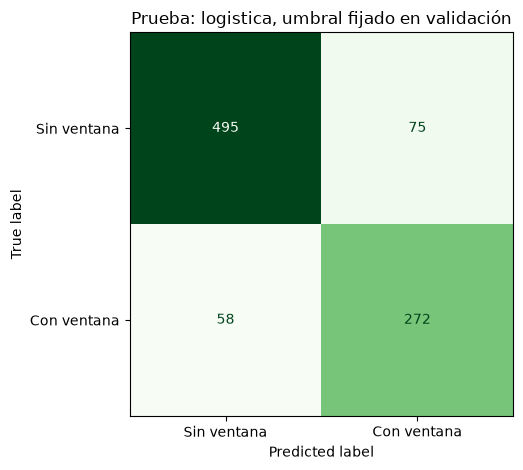

,thermal,beta,model,year,principal,n,positivos,prevalencia,avisos,VP,FP,FN,VN,precision,recall,F0.5,F1,Fbeta,Brier,average_precision
0,-3,0.5,logistica,2016,True,180,72,0.400000,75,57,18,15,90,0.760000,0.791667,0.766129,0.775510,0.766129,0.137488,0.785468
1,-3,0.5,logistica,2017,True,180,62,0.344444,64,56,8,6,110,0.875000,0.903226,0.880503,0.888889,0.880503,0.074737,0.938791
2,-3,0.5,logistica,2018,True,180,65,0.361111,71,51,20,14,95,0.718310,0.784615,0.730659,0.750000,0.730659,0.140767,0.700727
3,-3,0.5,logistica,2019,True,180,81,0.450000,79,64,15,17,84,0.810127,0.790123,0.806045,0.800000,0.806045,0.116767,0.863715
4,-3,0.5,logistica,2020,True,180,50,0.277778,58,44,14,6,116,0.758621,0.880000,0.780142,0.814815,0.780142,0.092397,0.829223


,thermal,beta,principal,comparador,metric,lower_2.5,upper_97.5,replicas_estimables,replicas_totales,fraction_not_estimable
42,-3,0.5,logistica,arbol,delta_F0.5,-0.012277,0.033829,1000,1000,0
43,-3,0.5,logistica,arbol,delta_F1,0.017158,0.073313,1000,1000,0
44,-3,0.5,logistica,arbol,delta_Brier,-0.017011,-0.003952,1000,1000,0
45,-3,0.5,logistica,frecuencia_mensual,delta_F0.5,0.063611,0.210152,1000,1000,0
46,-3,0.5,logistica,frecuencia_mensual,delta_F1,0.079050,0.257878,1000,1000,0
47,-3,0.5,logistica,frecuencia_mensual,delta_Brier,-0.082254,-0.043980,1000,1000,0
48,-3,0.5,logistica,knn,delta_F0.5,0.009611,0.051238,1000,1000,0
49,-3,0.5,logistica,knn,delta_F1,0.029891,0.084392,1000,1000,0
50,-3,0.5,logistica,knn,delta_Brier,-0.018679,-0.005898,1000,1000,0
51,-3,0.5,logistica,mezcla,delta_F0.5,-0.002743,0.022468,1000,1000,0


,thermal,beta,model,principal,tau,n,positivos,prevalencia,avisos,VP,FP,FN,VN,precision,recall,F0.5,F1,Fbeta,Brier,average_precision
0,-3,0.5,logistica,True,0.551970,900,330,0.366667,347,272,75,58,495,0.783862,0.824242,0.791618,0.803545,0.791618,0.112431,0.824242
15,-2,0.5,mezcla,True,0.719407,900,422,0.468889,359,312,47,110,431,0.869081,0.739336,0.839612,0.798976,0.839612,0.120156,0.878003
24,-4,0.5,logistica,True,0.535831,900,255,0.283333,227,160,67,95,578,0.704846,0.627451,0.687876,0.663900,0.687876,0.117457,0.718646


,thermal,beta,model,principal,tau,n,positivos,prevalencia,avisos,VP,FP,FN,VN,precision,recall,F0.5,F1,Fbeta,Brier,average_precision
6,-3,1.0,logistica,False,0.436735,900,330,0.366667,404,295,109,35,461,0.730198,0.893939,0.757965,0.803815,0.803815,0.112431,0.824242
7,-3,1.0,arbol,False,0.437500,900,330,0.366667,423,295,128,35,442,0.697400,0.893939,0.729476,0.783533,0.783533,0.122625,0.764164
8,-3,1.0,knn,False,0.419355,900,330,0.366667,421,292,129,38,441,0.693587,0.884848,0.724926,0.777630,0.777630,0.123214,0.778878
9,-3,1.0,mezcla,True,0.388272,900,330,0.366667,422,302,120,28,450,0.715640,0.915152,0.748266,0.803191,0.803191,0.113003,0.823842
10,-3,1.0,frecuencia_mensual,False,0.454839,900,330,0.366667,460,266,194,64,376,0.578261,0.806061,0.612903,0.673418,0.673418,0.165874,0.661811
11,-3,1.0,persistencia,False,0.500000,900,330,0.366667,330,236,94,94,476,0.715152,0.715152,0.715152,0.715152,0.715152,0.208889,0.615886


{
  "alcance": "Descripcion posterior de salidas, sin nuevas decisiones de ajuste",
  "thermal": -3,
  "beta": 0.5,
  "n": 900,
  "desacuerdo_avisos_logistica_arbol": 56,
  "fraccion_desacuerdo": 0.06222222222222222,
  "episodios_prueba": 35,
  "episodios_por_ano": {
    "2016": 10,
    "2017": 4,
    "2018": 8,
    "2019": 8,
    "2020": 5
  },
  "subventanas_en_episodios": 330,
  "positivos_prueba": 330,
  "episodios_tocan_borde": 0
}


In [31]:
fila = principal_test.set_index("model").loc[principal]
matriz = np.array([[int(fila.VN), int(fila.FP)], [int(fila.FN), int(fila.VP)]])
ConfusionMatrixDisplay(matriz, display_labels=["Sin ventana", "Con ventana"]).plot(
    cmap="Greens", colorbar=False
)
plt.title(f"Prueba: {principal}, umbral fijado en validación")
plt.tight_layout()
plt.savefig(OUT / "matriz_confusion_principal.png", dpi=160)
plt.show()
display(
    pd.read_csv(OUT / "metricas_prueba_anuales.csv").query(
        "thermal == -3 and beta == 0.5 and model == @principal"
    )
)
display(
    pd.read_csv(OUT / "bootstrap_intervalos_diferencias.csv").query(
        "thermal == -3 and beta == 0.5"
    )
)
display(metricas.query("beta == 0.5 and principal"))
display(metricas.query("thermal == -3 and beta == 1"))
print((OUT / "resumen_descriptivo.json").read_text(encoding="utf-8"))


## 13. Contrastar con las cifras publicadas
Esta comparación ocurre **después** de calcular la prueba y no interviene en el aprendizaje. Verifica los resultados principales del informe. Si algo cambia, se informa: no se retocan umbrales para forzar la coincidencia.

In [32]:
referencia = pd.DataFrame(
    [
        ("logistica", 0.791618160652, 0.112431201147, 272, 75, 58, 495),
        ("arbol", 0.781452658885, 0.122625183315, 241, 62, 89, 508),
        ("knn", 0.763090676884, 0.123214244421, 239, 70, 91, 500),
        ("mezcla", 0.78323699422, 0.113003361877, 271, 79, 59, 491),
        ("frecuencia_mensual", 0.667741935484, 0.165874192073, 207, 98, 123, 472),
        ("persistencia", 0.715151515152, 0.208888888889, 236, 94, 94, 476),
    ],
    columns=["model", "F0.5", "Brier", "VP", "FP", "FN", "VN"],
).set_index("model")
actual = principal_test.set_index("model").loc[referencia.index, referencia.columns]
coinciden = np.allclose(
    actual[["F0.5", "Brier"]], referencia[["F0.5", "Brier"]], rtol=1e-7, atol=1e-8
)
conteos_iguales = actual[["VP", "FP", "FN", "VN"]].equals(
    referencia[["VP", "FP", "FN", "VN"]]
)
verificacion = {
    "fuente": "NetCDF originales leídos en esta ejecución",
    "hashes_originales_coinciden": all(
        manifest[v]["sha256"] == SHA_ORIGINALES[v] for v in SHA_ORIGINALES
    ),
    "metricas_principales_coinciden": bool(coinciden),
    "conteos_principales_coinciden": bool(conteos_iguales),
    "ejecucion_en_colab": EN_COLAB,
    "code_sha256": frozen["code_sha256"],
}
write_json(OUT / "verificacion_informe.json", verificacion)
display(actual)
if not coinciden or not conteos_iguales:
    raise AssertionError(
        "Las cifras difieren del informe. Conserva la salida para analizar la causa; no ajustes con prueba."
    )
print("VERIFICADO: las cifras principales coinciden con el informe.")


,F0.5,Brier,VP,FP,FN,VN
model,,,,,,
logistica,0.791618,0.112431,272,75,58,495
arbol,0.781453,0.122625,241,62,89,508
knn,0.763091,0.123214,239,70,91,500
mezcla,0.783237,0.113003,271,79,59,491
frecuencia_mensual,0.667742,0.165874,207,98,123,472
persistencia,0.715152,0.208889,236,94,94,476


VERIFICADO: las cifras principales coinciden con el informe.


## 14. Exportar resultados
Se incluyen datos extraídos, control de calidad, decisiones de preprocesamiento, parámetros de escalado, código ejecutado, validación, decisiones congeladas, predicciones y resultados. El ZIP permite revisar qué ocurrió en tu propia ejecución. Los NetCDF originales permanecen en Drive y no se copian al ZIP.

In [33]:
archivo_zip = shutil.make_archive("resultados_grupo9_drive", "zip", OUT)
print("Resultados guardados:", archivo_zip)
if EN_COLAB:
    from google.colab import files

    files.download(archivo_zip)


Resultados guardados: C:\Users\51924\Documents\Codex\2026-09-08\deep-research-plugin-deep-research-work\work\entrega_final\ejecucion_drive\resultados_grupo9_drive.zip


## Fuentes y alcance
- Huerta et al. (2023), PISCOt v1.2: https://doi.org/10.1038/s41597-023-02777-w
- Serie oficial 010: https://doi.org/10.6084/m9.figshare.22712365.v3
- Scikit-learn, escalado: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- Scikit-learn, prevención de fuga: https://scikit-learn.org/stable/common_pitfalls.html#data-leakage

La etiqueta describe una condición térmica reconstruida del aire en una celda. El éxito de un lote de chuño requiere validación de parcelas y tubérculos. Los resultados de este notebook no cuantifican pérdidas económicas evitadas.